In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier


In [121]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print(df)

      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL             No  ...   
1        

In [122]:
# TotalCharges ko numeric mein convert karein
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")
df = df.drop("customerID", axis=1)
df = df.dropna(subset=["Churn"])
print(df.isnull().sum())
print("\nChurn counts:\n", df["Churn"].value_counts())
print(df.columns)
print(df.info())

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Churn counts:
 Churn
No     5174
Yes    1869
Name: count, dtype: int64
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (

In [123]:
df = pd.get_dummies(df,columns=["gender","Partner","Dependents",'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'],drop_first=True)
print(df)

      SeniorCitizen  tenure  MonthlyCharges  TotalCharges Churn  gender_Male  \
0                 0       1           29.85         29.85    No        False   
1                 0      34           56.95       1889.50    No         True   
2                 0       2           53.85        108.15   Yes         True   
3                 0      45           42.30       1840.75    No         True   
4                 0       2           70.70        151.65   Yes        False   
...             ...     ...             ...           ...   ...          ...   
7038              0      24           84.80       1990.50    No         True   
7039              0      72          103.20       7362.90    No        False   
7040              0      11           29.60        346.45    No        False   
7041              1       4           74.40        306.60   Yes         True   
7042              0      66          105.65       6844.50    No         True   

      Partner_Yes  Dependents_Yes  Phon

In [124]:
X = df.drop("Churn", axis=1)


y = df["Churn"].map({"No": 0, "Yes": 1})

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (5634, 30)
Testing shape: (1409, 30)


In [125]:

numeric_cols = x_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_cols = x_train.select_dtypes(
    include=["object"]
).columns


numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])


categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

In [126]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report, confusion_matrix


rf_pred = rf_model.predict(x_test)
rf_prob = rf_model.predict_proba(x_test)[:, 1]


rf_auc = roc_auc_score(y_test, rf_prob)

print(f"ROC-AUC Score: {rf_auc:.4f}\n")
print("Classification Report:\n")
print(classification_report(y_test, rf_pred))

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(x_train, y_train)


rf_pred = rf_model.predict(x_test)
rf_prob = rf_model.predict_proba(x_test)[:, 1]


rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Results")
print("ROC-AUC:", rf_auc)
print("\nClassification Report:\n")
print(classification_report(y_test, rf_pred))

ROC-AUC Score: 0.7753

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.88      0.85      1035
           1       0.57      0.45      0.50       374

    accuracy                           0.76      1409
   macro avg       0.69      0.66      0.67      1409
weighted avg       0.75      0.76      0.75      1409

Random Forest Results
ROC-AUC: 0.7752641504559664

Classification Report:

              precision    recall  f1-score   support

           0       0.82      0.88      0.85      1035
           1       0.57      0.45      0.50       374

    accuracy                           0.76      1409
   macro avg       0.69      0.66      0.67      1409
weighted avg       0.75      0.76      0.75      1409



In [127]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_cv_scores = cross_val_score(rf_model,x_train,y_train,cv=cv,scoring="roc_auc",
    n_jobs=-1
)

print(" scores:", rf_cv_scores)
print(rf_cv_scores.mean())

 scores: [0.7757521  0.76129772 0.78946125 0.79207261 0.78804398]
0.7813255337042547


In [128]:
from xgboost import XGBClassifier


negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

class_weight_ratio = negative_count / positive_count

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=class_weight_ratio,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])


xgb_model.fit(x_train, y_train)


xgb_pred = xgb_model.predict(x_test)
xgb_prob = xgb_model.predict_proba(x_test)[:, 1]


xgb_auc = roc_auc_score(y_test, xgb_prob)

print("XGBoost Results")
print("ROC-AUC:", xgb_auc)
print("\nClassification Report:\n")
print(classification_report(y_test, xgb_pred))

XGBoost Results
ROC-AUC: 0.8258066599498824

Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.77      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.79      0.73      0.75      1409



In [129]:
xgb_cv_scores = cross_val_score(
    xgb_model,
    x_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1
)

print("XGBoost CV ROC-AUC scores:", xgb_cv_scores)
print("XGBoost Mean CV ROC-AUC:", xgb_cv_scores.mean())

XGBoost CV ROC-AUC scores: [0.82129037 0.79064272 0.81784087 0.83521157 0.8303171 ]
XGBoost Mean CV ROC-AUC: 0.8190605276950347


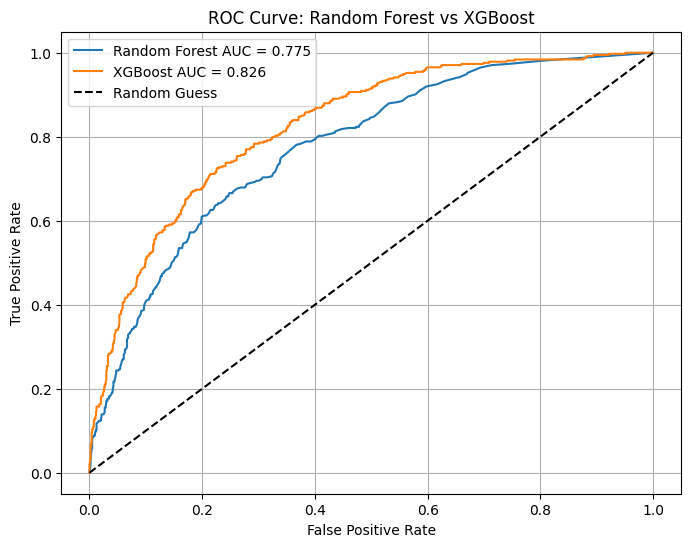

In [130]:
from sklearn.metrics import roc_curve
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)

plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr,label=f"Random Forest AUC = {rf_auc:.3f}"
)

plt.plot(xgb_fpr, xgb_tpr,
label=f"XGBoost AUC = {xgb_auc:.3f}"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Random Forest vs XGBoost")
plt.legend()
plt.grid()
plt.show()

In [131]:
results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Test ROC-AUC": [rf_auc, xgb_auc],
    "Mean CV ROC-AUC": [
        rf_cv_scores.mean(),
        xgb_cv_scores.mean()
    ]
})

print(results.round(4))

           Model  Test ROC-AUC  Mean CV ROC-AUC
0  Random Forest        0.7753           0.7813
1        XGBoost        0.8258           0.8191
